# Recurrent Neural Networks
You should build an end-to-end machine learning pipeline using a recurrent neural network model. In particular, you should do the following:
- Load the `jena climate` dataset using [Pandas](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html). You can find this dataset in the [keras repository](https://keras.io/examples/timeseries/timeseries_weather_forecasting/).
- Split the dataset into training, validation, and test sets. Note that you cannot split time series using [Scikit-Learn](https://keras.io/examples/timeseries/timeseries_weather_forecasting/).
- Build an end-to-end machine learning pipeline, including a [recurrent neural network](https://keras.io/examples/timeseries/timeseries_weather_forecasting/) model.
- Optimize your pipeline by validating your design decisions.
- Test the best pipeline on the test set and report various [evaluation metrics](https://scikit-learn.org/0.15/modules/model_evaluation.html).  
- Check the documentation to identify the most important hyperparameters, attributes, and methods of the model. Use them in practice.

In [1]:
import pandas as pd
import keras

from zipfile import ZipFile

uri = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
zip_path = keras.utils.get_file(origin=uri, fname="jena_climate_2009_2016.csv.zip")
zip_file = ZipFile(zip_path)
zip_file.extractall()
csv_path = "jena_climate_2009_2016.csv"

df = pd.read_csv(csv_path)
df.head()

13568290/13568290 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,Date Time,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
0,01.01.2009 00:10:00,996.52,-8.02,265.40,-8.90,93.3,3.33,3.11,0.22,1.94,3.12,1307.75,1.03,1.75,152.3
1,01.01.2009 00:20:00,996.57,-8.41,265.01,-9.28,93.4,3.23,3.02,0.21,1.89,3.03,1309.80,0.72,1.50,136.1
2,01.01.2009 00:30:00,996.53,-8.51,264.91,-9.31,93.9,3.21,3.01,0.20,1.88,3.02,1310.24,0.19,0.63,171.6
3,01.01.2009 00:40:00,996.51,-8.31,265.12,-9.07,94.2,3.26,3.07,0.19,1.92,3.08,1309.19,0.34,0.50,198.0
4,01.01.2009 00:50:00,996.51,-8.27,265.15,-9.04,94.1,3.27,3.08,0.19,1.92,3.09,1309.00,0.32,0.63,214.3


**Sample One Data Point Per Day**

In [5]:
df["Date Time"] = pd.to_datetime(
    df["Date Time"],
    format="%d.%m.%Y %H:%M:%S"
)

df_daily = df[
    (df["Date Time"].dt.hour == 12) &
    (df["Date Time"].dt.minute == 0)
].copy()

df_daily = df_daily.reset_index(drop=True)

df_daily.head()

print("Original rows:", len(df))
print("Daily sampled rows:", len(df_daily))

print(df_daily[["Date Time", "T (degC)"]].head(10))

print(
    "Unique dates:",
    df_daily["Date Time"].dt.date.nunique()
)

print(
    "Total sampled rows:",
    len(df_daily)
)

Original rows: 420551
Daily sampled rows: 2921
            Date Time  T (degC)
0 2009-01-01 12:00:00     -6.87
1 2009-01-02 12:00:00     -3.12
2 2009-01-03 12:00:00     -5.96
3 2009-01-04 12:00:00     -1.21
4 2009-01-05 12:00:00     -3.65
5 2009-01-06 12:00:00    -14.52
6 2009-01-07 12:00:00    -16.50
7 2009-01-08 12:00:00     -6.84
8 2009-01-09 12:00:00    -10.47
9 2009-01-10 12:00:00     -7.48
Unique dates: 2918
Total sampled rows: 2921


**Create a Target Label Column Using Shift**

In [9]:
df_daily["Target"] = df_daily["T (degC)"].shift(-1)

df_daily.head(10)

df_daily = df_daily.dropna(subset=["Target"]).reset_index(drop=True)

df_daily.tail()

#shifting verification
print(
    df_daily[["Date Time", "T (degC)", "Target"]].head(10)
)

print("Total rows:", len(df_daily))

            Date Time  T (degC)  Target
0 2009-01-01 12:00:00     -6.87   -3.12
1 2009-01-02 12:00:00     -3.12   -5.96
2 2009-01-03 12:00:00     -5.96   -1.21
3 2009-01-04 12:00:00     -1.21   -3.65
4 2009-01-05 12:00:00     -3.65  -14.52
5 2009-01-06 12:00:00    -14.52  -16.50
6 2009-01-07 12:00:00    -16.50   -6.84
7 2009-01-08 12:00:00     -6.84  -10.47
8 2009-01-09 12:00:00    -10.47   -7.48
9 2009-01-10 12:00:00     -7.48   -7.12
Total rows: 2918


**Split Data into Training, Validation, and Test Sets**

In [12]:
# Sort data chronologically
df_daily = df_daily.sort_values(
    "Date Time"
).reset_index(drop=True)

# Calculate split positions
n = len(df_daily)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Split data chronologically
# Exclude boundary rows to prevent target leakage
train_df = df_daily.iloc[:train_end - 1].copy()

val_df = df_daily.iloc[train_end:val_end - 1].copy()

test_df = df_daily.iloc[val_end:].copy()

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

print("\nTraining period:")
print(train_df["Date Time"].min(), "to",
      train_df["Date Time"].max())

print("\nValidation period:")
print(val_df["Date Time"].min(), "to",
      val_df["Date Time"].max())

print("\nTesting period:")
print(test_df["Date Time"].min(), "to",
      test_df["Date Time"].max())


# Exclude the date and target columns
feature_cols = [
    col for col in df_daily.columns
    if col not in ["Date Time", "Target"]
]

# Input features
X_train = train_df[feature_cols]
X_val = val_df[feature_cols]
X_test = test_df[feature_cols]

# Target labels
y_train = train_df["Target"]
y_val = val_df["Target"]
y_test = test_df["Target"]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)


Training samples: 2041
Validation samples: 437
Testing samples: 438

Training period:
2009-01-01 12:00:00 to 2014-07-31 12:00:00

Validation period:
2014-08-02 12:00:00 to 2015-10-12 12:00:00

Testing period:
2015-10-14 12:00:00 to 2016-12-28 12:00:00
X_train: (2041, 14)
X_val: (437, 14)
X_test: (438, 14)


**Create Input Sequence Matrices for LSTM/GRU**

In [15]:
import numpy as np
import keras

sequence_length = 14
batch_size = 32

def create_sequences(X, y):
    X_array = X.to_numpy(dtype=np.float32)
    y_array = y.to_numpy(dtype=np.float32)

    dataset = keras.utils.timeseries_dataset_from_array(
        data=X_array,
        targets=y_array[sequence_length - 1:],
        sequence_length=sequence_length,
        sequence_stride=1,
        sampling_rate=1,
        batch_size=batch_size,
        shuffle=False
    )

    return dataset

# Create training sequences
train_dataset = create_sequences(X_train, y_train)

# Create validation sequences
val_dataset = create_sequences(X_val, y_val)

# Create testing sequences
test_dataset = create_sequences(X_test, y_test)

for inputs, targets in train_dataset.take(1):
    print("Input shape:", inputs.shape)
    print("Target shape:", targets.shape)

    print("First input sequence:")
    print(inputs[0].numpy())

    print("First target:")
    print(targets[0].numpy())

print("Training sequences:",
      len(X_train) - sequence_length + 1)

print("Validation sequences:",
      len(X_val) - sequence_length + 1)

print("Testing sequences:",
      len(X_test) - sequence_length + 1)

Input shape: (32, 14, 14)
Target shape: (32,)
First input sequence:
[[ 1.00030e+03 -6.87000e+00  2.66270e+02 -8.28000e+00  8.96000e+01
   3.64000e+00  3.27000e+00  3.80000e-01  2.03000e+00  3.26000e+00
   1.30698e+03  1.84000e+00  2.63000e+00  1.84400e+02]
 [ 9.98910e+02 -3.12000e+00  2.70130e+02 -4.50000e+00  9.01000e+01
   4.85000e+00  4.37000e+00  4.80000e-01  2.73000e+00  4.38000e+00
   1.28647e+03  1.54000e+00  2.00000e+00  1.27000e+02]
 [ 9.99020e+02 -5.96000e+00  2.67280e+02 -8.72000e+00  8.07000e+01
   3.91000e+00  3.16000e+00  7.50000e-01  1.97000e+00  3.16000e+00
   1.30090e+03  1.31000e+00  1.88000e+00  2.13900e+02]
 [ 9.88940e+02 -1.21000e+00  2.72820e+02 -2.36000e+00  9.18000e+01
   5.59000e+00  5.13000e+00  4.60000e-01  3.23000e+00  5.19000e+00
   1.26430e+03  1.99000e+00  3.88000e+00  2.25800e+02]
 [ 9.90420e+02 -3.65000e+00  2.70260e+02 -5.54000e+00  8.66000e+01
   4.66000e+00  4.04000e+00  6.20000e-01  2.54000e+00  4.08000e+00
   1.27821e+03  5.49000e+00  8.38000e+00  

**Design and Train an LSTM Model**

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_2 (Normalization) │ (None, 14, 14)         │            29 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,366 (87.37 KB)

 Trainable params: 22,337 (87.25 KB)

 Non-trainable params: 29 (120.00 B)

Epoch 1/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 140.7485 - mae: 9.8862 - val_loss: 50.5811 - val_mae: 5.5626
Epoch 2/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 36.7047 - mae: 4.8512 - val_loss: 23.6325 - val_mae: 3.5989
Epoch 3/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 20.7701 - mae: 3.6004 - val_loss: 16.7158 - val_mae: 3.1297
Epoch 4/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 16.3067 - mae: 3.1949 - val_loss: 14.5173 - val_mae: 2.9624
Epoch 5/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 14.4907 - mae: 3.0013 - val_loss: 13.3406 - val_mae: 2.8555
Epoch 6/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 13.2722 - mae: 2.8587 - val_loss: 12.6752 - val_mae: 2.7702
Epoch 7/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 12.4345 - mae: 2.7563 - val_loss: 12.3406 - val_mae: 2.7184
Epoch 8/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 11.8549 - mae: 2.6914 - val_loss: 12.1024 - val_mae: 2.6895
Epoch 9/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/s

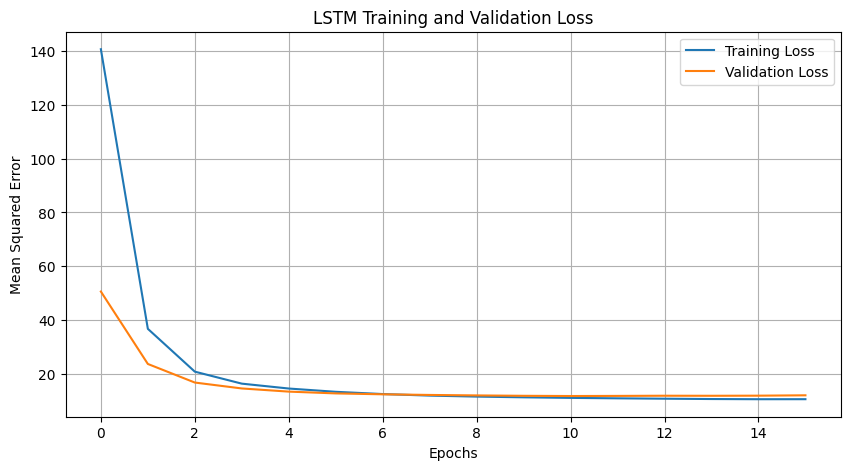

Best Epoch: 11
Best Validation Loss: 11.699719429016113
Validation MAE at Best Epoch: 2.648561477661133
Training Time: 18.39010000228882
Restored Model Validation Loss: 11.699719429016113
Restored Model Validation MAE: 2.648561477661133


In [18]:
import tensorflow as tf
import numpy as np

# Number of features
n_features = X_train.shape[1]

# Normalize using training data only
normalizer = tf.keras.layers.Normalization(axis=-1)

normalizer.adapt(
    X_train.to_numpy(dtype=np.float32)
)

# Build LSTM model
model = tf.keras.Sequential([
    tf.keras.layers.Input(
        shape=(14, n_features)
    ),

    normalizer,

    tf.keras.layers.LSTM(64),

    tf.keras.layers.Dense(
        32, activation='relu'
    ),

    tf.keras.layers.Dense(1)
])

model.summary()

#compiling model
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss='mse',
    metrics=['mae']
)

#early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

#trainig
import time

start_time = time.time()

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=50,
    callbacks=[early_stopping]
)

training_time = time.time() - start_time

print(f"Training Time: {training_time:.2f} seconds")
print("Epochs Trained:", len(history.history['loss']))

#presentation
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epochs')
plt.ylabel('Mean Squared Error')
plt.title('LSTM Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.show()


import numpy as np

best_epoch = np.argmin(history.history["val_loss"])

print("Best Epoch:", best_epoch + 1)

print(
    "Best Validation Loss:",
    history.history["val_loss"][best_epoch]
)

print(
    "Validation MAE at Best Epoch:",
    history.history["val_mae"][best_epoch]
)

print("Training Time:", training_time)

val_loss, val_mae = model.evaluate(
    val_dataset,
    verbose=0
)

print("Restored Model Validation Loss:", val_loss)
print("Restored Model Validation MAE:", val_mae)

**Experiment with Design Decisions and Report Results**


Running: E1: Baseline LSTM

Running: E2: GRU

Running: E3: Fewer units

Running: E4: Dropout

Running: E5: Learning rate


,Experiment,Training Time (s),Epochs Trained,Best Epoch,Validation MSE,Validation MAE
0,E1: Baseline LSTM,22.41,18,13,11.7348,2.6206
1,E2: GRU,32.00,25,20,10.5477,2.5333
2,E3: Fewer units,24.64,23,18,11.9042,2.6622
3,E4: Dropout,26.86,21,16,11.9295,2.6728
4,E5: Learning rate,29.89,25,20,12.4156,2.6766


Best Configuration:
Experiment           E2: GRU
Training Time (s)       32.0
Epochs Trained            25
Best Epoch                20
Validation MSE       10.5477
Validation MAE        2.5333
Name: 1, dtype: object


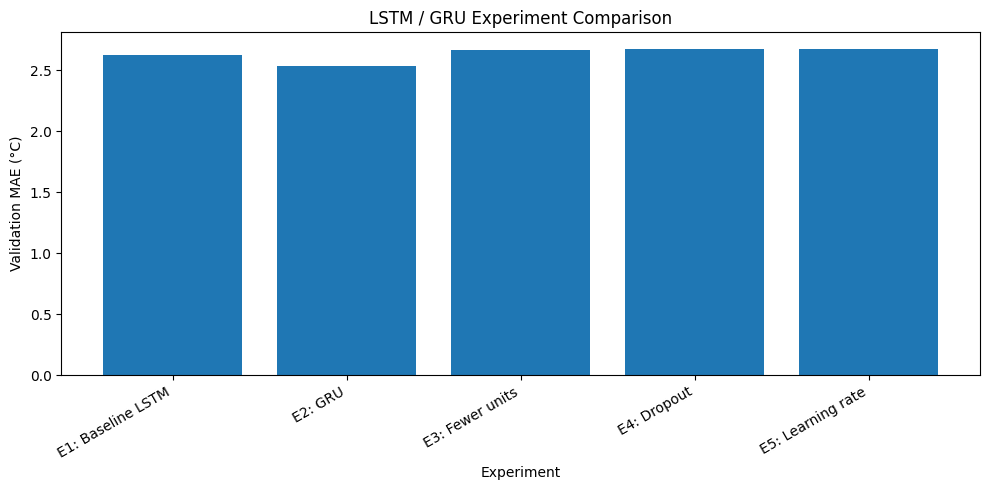

In [19]:
import tensorflow as tf
import numpy as np
import pandas as pd
import time

# Define experiments
experiments = [
    ("E1: Baseline LSTM", "LSTM", 64, 0.0, 0.001),
    ("E2: GRU",           "GRU",  64, 0.0, 0.001),
    ("E3: Fewer units",   "LSTM", 32, 0.0, 0.001),
    ("E4: Dropout",       "LSTM", 64, 0.3, 0.001),
    ("E5: Learning rate", "LSTM", 64, 0.0, 0.0005)
]

def build_model(model_type, units, dropout, learning_rate):

    normalizer = tf.keras.layers.Normalization(axis=-1)
    normalizer.adapt(
        X_train.to_numpy(dtype=np.float32)
    )

    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(
        shape=(sequence_length, X_train.shape[1])
    ))

    model.add(normalizer)

    if model_type == "LSTM":
        model.add(tf.keras.layers.LSTM(units))
    else:
        model.add(tf.keras.layers.GRU(units))

    if dropout > 0:
        model.add(tf.keras.layers.Dropout(dropout))

    model.add(tf.keras.layers.Dense(32, activation="relu"))
    model.add(tf.keras.layers.Dense(1))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model


results = []

for name, model_type, units, dropout, lr in experiments:

    print("\nRunning:", name)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    experiment_model = build_model(
        model_type, units, dropout, lr
    )

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    start = time.perf_counter()

    history = experiment_model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=50,
        callbacks=[early_stop],
        verbose=0
    )

    training_time = time.perf_counter() - start

    # Evaluate restored best weights on validation data
    val_mse, val_mae = experiment_model.evaluate(
        val_dataset, verbose=0
    )

    best_epoch = np.argmin(
        history.history["val_loss"]
    ) + 1

    results.append({
        "Experiment": name,
        "Training Time (s)": round(training_time, 2),
        "Epochs Trained": len(history.history["loss"]),
        "Best Epoch": best_epoch,
        "Validation MSE": round(val_mse, 4),
        "Validation MAE": round(val_mae, 4)
    })

# Display comparison
results_df = pd.DataFrame(results)

display(results_df)

# Lower MAE means better validation performance
best_result = results_df.loc[
    results_df["Validation MAE"].idxmin()
]

print("Best Configuration:")
print(best_result)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Experiment"],
    results_df["Validation MAE"]
)

plt.xlabel("Experiment")
plt.ylabel("Validation MAE (°C)")
plt.title("LSTM / GRU Experiment Comparison")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [20]:
# Select best experiment using validation MAE
best_name = results_df.loc[
    results_df["Validation MAE"].idxmin(),
    "Experiment"
]

print("Best Experiment:", best_name)

# Find its configuration
best_config = next(
    exp for exp in experiments
    if exp[0] == best_name
)

# Build fresh model with selected settings
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

best_model = build_model(*best_config[1:])

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_best = best_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=50,
    callbacks=[early_stop],
    verbose=1
)


test_mse, test_mae = best_model.evaluate(
    test_dataset,
    verbose=0
)

test_rmse = np.sqrt(test_mse)

print("Test MSE:", round(test_mse, 4))
print("Test MAE:", round(test_mae, 4), "°C")
print("Test RMSE:", round(test_rmse, 4), "°C")

from sklearn.metrics import r2_score

# Actual temperatures
y_true = np.concatenate([
    y.numpy() for x, y in test_dataset
])

# Predicted temperatures
y_pred = best_model.predict(
    test_dataset,
    verbose=0
).flatten()

r2 = r2_score(y_true, y_pred)

print("Test R² Score:", round(r2, 4))

Best Experiment: E2: GRU
Epoch 1/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 171.7643 - mae: 11.1219 - val_loss: 90.1414 - val_mae: 7.9819
Epoch 2/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 43.8781 - mae: 5.3600 - val_loss: 26.7561 - val_mae: 3.9546
Epoch 3/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - loss: 22.0168 - mae: 3.7194 - val_loss: 17.0609 - val_mae: 3.2000
Epoch 4/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - loss: 15.8896 - mae: 3.1522 - val_loss: 13.5719 - val_mae: 2.8852
Epoch 5/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - loss: 13.5390 - mae: 2.9006 - val_loss: 12.3318 - val_mae: 2.7345
Epoch 6/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 12.2857 - mae: 2.7478 - val_loss: 11.6979 - val_mae: 2.6555
Epoch 7/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 11.5364 - mae: 2.6531 - val_loss: 11.3920 - val_mae: 2.6254
Epoch 8/50
64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 11.1201 - mae: 2.6007 - val_loss: 11.2103 - val_mae: 2.6056
Epoch 9/50
64/64 ━━━━

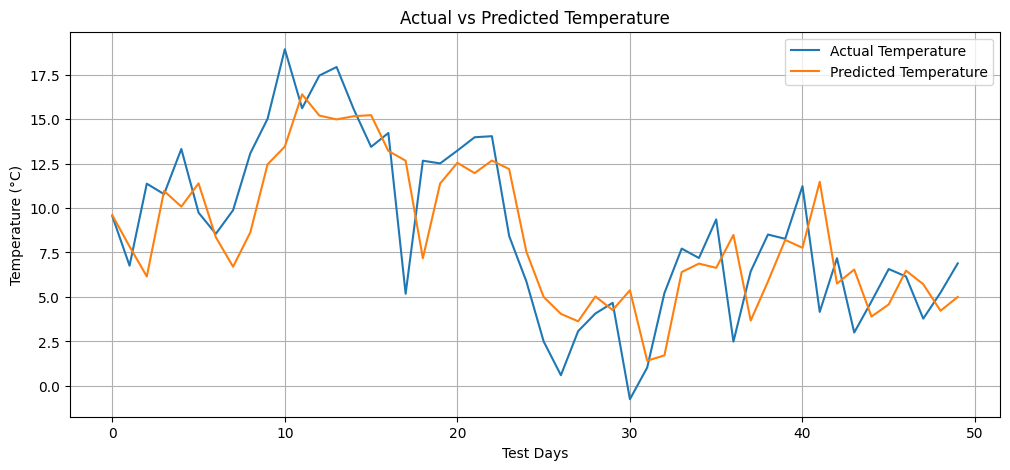

,Metric,Result
0,Test MAE (°C),2.3899
1,Test MSE (°C²),8.7851
2,Test RMSE (°C),2.9640
3,Test R²,0.8706


In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_true[:50],
    label="Actual Temperature"
)

plt.plot(
    y_pred[:50],
    label="Predicted Temperature"
)

plt.xlabel("Test Days")
plt.ylabel("Temperature (°C)")
plt.title("Actual vs Predicted Temperature")
plt.legend()
plt.grid(True)
plt.show()

final_results = pd.DataFrame({
    "Metric": [
        "Test MAE (°C)",
        "Test MSE (°C²)",
        "Test RMSE (°C)",
        "Test R²"
    ],
    "Result": [
        round(test_mae, 4),
        round(test_mse, 4),
        round(test_rmse, 4),
        round(r2, 4)
    ]
})

display(final_results)